<div align = 'center'>
<h1>Health in Nature and People in London Boroughs</h1>
</div>
<ul>
<li><em>Student ID:</em> 24000117484</li>
<li><em>Repository:</em> M6006-ds2026-24000117484</li>
</ul>



<div align = 'center'>
<h1> Research Question</h1>  <h2>What Effect does Green Space have on the Health of London Borough Residents, How strong is that effect and are there any other factors involved</h2>


In [28]:
import numpy as np
import pandas as pd
import plotly.express as px

## Cleaning

In [2]:
#health = pd.read_csv('Data/la_health.csv')
demo = pd.read_excel('Data/File_10_-_IoD2025_Local_Authority_District_Summaries__lower-tier__v2.xlsx', sheet_name=['Health', 'Income'])

health = demo['Health']
health = health[health['Local Authority District code (2024)'].str.contains('E09', na=False)]

wealth = demo['Income']
wealth = wealth[wealth['Local Authority District code (2024)'].str.contains('E09', na=False)]

#g_cover = pd.read_csv('Data/g_cover.csv')
g_cover = pd.read_excel('Data/green_cover_borough_summary_0.05.xlsx', sheet_name='borough_green_cover')


In [3]:
g_cover.head()

,lb_code,lb_name,borough_area_hectare,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue
0,Havering,E09000016,11445.736,7551.971148,401.810236,7953.781384,65.980651,3.510567,69.491218
1,Bromley,E09000006,15013.487,10262.639922,56.961015,10319.600937,68.356138,0.379399,68.735537
2,Richmond upon Thames,E09000027,5876.109,3642.676453,307.938502,3950.614955,61.991302,5.240517,67.231819
3,Barnet,E09000003,8674.835,5030.909762,60.010101,5090.919864,57.994299,0.691772,58.686071
4,Enfield,E09000010,8220.024,4352.729074,424.013507,4776.742581,52.952754,5.158300,58.111054


In [4]:
# Printing column names

print('wealth: ', wealth.columns, '\nhealth:', health.columns, '\ngreen cover:', g_cover.columns)

wealth:  Index(['Local Authority District code (2024)',
       'Local Authority District name (2024)', 'Income - Average rank ',
       'Income - Rank of average rank ', 'Income - Average score ',
       'Income - Rank of average score ',
       'Income - Proportion of LSOAs in most deprived 10% nationally ',
       'Income - Rank of proportion of LSOAs in most deprived 10% nationally ',
       'Income scale', 'Rank of Income Scale'],
      dtype='str') 
health: Index(['Local Authority District code (2024)',
       'Local Authority District name (2024)',
       'Health Deprivation and Disability - Average rank ',
       'Health Deprivation and Disability - Rank of average rank ',
       'Health Deprivation and Disability - Average score ',
       'Health Deprivation and Disability - Rank of average score ',
       'Health Deprivation and Disability - Proportion of LSOAs in most deprived 10% nationally ',
       'Health Deprivation and Disability - Rank of proportion of LSOAs in most de

In [5]:
# Fixing incorrect column names
g_cover = g_cover.rename(columns={
    'lb_code': 'borough',
    'lb_name': 'lb_code'
})

# Simplifying and matching column names for borough names
health = health.rename(columns={
    'Local Authority District name (2024)': 'borough',
})

wealth = wealth.rename(columns={
    'Local Authority District name (2024)': 'borough',
    
})



In [6]:
# Eliminating white space and capitals in column titles and borough names for ease
def clean_text(s):
    return s.astype("string").str.strip().str.lower()

wealth.columns = clean_text(wealth.columns)
wealth['borough'] = clean_text(wealth['borough'])

health.columns = clean_text(health.columns)
health['borough'] = clean_text(health['borough'])

g_cover.columns = clean_text(g_cover.columns)
g_cover['borough'] = clean_text(g_cover['borough'])

In [7]:
health.columns

Index(['local authority district code (2024)', 'borough',
       'health deprivation and disability - average rank',
       'health deprivation and disability - rank of average rank',
       'health deprivation and disability - average score',
       'health deprivation and disability - rank of average score',
       'health deprivation and disability - proportion of lsoas in most deprived 10% nationally',
       'health deprivation and disability - rank of proportion of lsoas in most deprived 10% nationally'],
      dtype='string')

In [8]:
# Checking both datasets are the same length

print(len(health['borough']) - len(wealth['borough']))
print(len(g_cover['borough']) - len(health['borough']))

0
0


In [9]:
# Creatng a list of the London Boroughs

boroughs = g_cover['borough'] 


In [10]:
N = len(health['borough']) # Length of health and wealth borough columns, both are the same length so only one needed
G = len(g_cover) # Length of g_cover borough dataset (actual number of boroughs in London)


# Creating a list of all rows that match the values in 'boroughs' and setting the datasets to only contain those rows

lbs_h = health['borough'].isin(boroughs)
health = health[lbs_h]

lbs_w = wealth['borough'].isin(boroughs)
wealth = wealth[lbs_w]





In [11]:
# Selecting only relevant columns for wealth and health
# Average score used as it is the best indicator for each dataset for the variable I want to identify

wealth = wealth.loc[:, [
    'borough', 'income - average score'
]]

health = health.loc[:, [
    'borough', 'health deprivation and disability - average score'
]]

# Merging wealth and health datasets

lb_demo = pd.merge(wealth, health, how='inner', on='borough')

# Merging demographics (wealth and health) dataset with green and blue cover dataset

data = pd.merge(g_cover, lb_demo, how='inner', on='borough')

In [12]:
data = data.assign(
    health_score=data['health deprivation and disability - average score']*-1,
    wealth_score=data['income - average score']*-1
).drop(columns=['income - average score', 'health deprivation and disability - average score'])

In [13]:
#Checking for any null values

print(' --------\nNull Values\n --------', '\n', data.isna().sum())


 --------
Null Values
 -------- 
 borough                    0
lb_code                    0
borough_area_hectare       0
green_area_hectare         0
blue _area_hectare         0
green+blue_area_hectare    0
percent_green              0
percent_blue               0
percent_green+blue         0
health_score               0
wealth_score               0
dtype: int64


In [ ]:
# Writing cleaned dataset to a file
data.to_csv('Data/borough_demographics.csv', index=False)

## Initial Analysis

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

data.columns

Index(['borough', 'lb_code', 'borough_area_hectare', 'green_area_hectare',
       'blue _area_hectare', 'green+blue_area_hectare', 'percent_green',
       'percent_blue', 'percent_green+blue', 'health_score', 'wealth_score'],
      dtype='string')

In [16]:
data1 = data.loc[:,[
    'green_area_hectare', 'blue _area_hectare', 'green+blue_area_hectare',
    'percent_green', 'percent_blue', 'percent_green+blue',
    'wealth_score', 'health_score', 'borough_area_hectare'
]]

In [17]:
data1.describe()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000
mean,2488.763528,142.141477,2630.905005,44.002749,3.261837,47.264587,-0.264937,0.273594,4914.585000
std,2261.739659,144.501396,2309.215064,12.814015,2.978149,11.729273,0.083482,0.439584,3294.747202
min,17.608124,3.952986,41.922343,5.590892,0.133674,13.311089,-0.401000,-0.602000,314.943000
25%,1080.791988,31.084234,1180.601695,38.511252,0.894107,41.012407,-0.307500,-0.055500,2901.113000
50%,1780.961490,58.485558,1915.365506,43.412392,2.270448,47.464324,-0.266000,0.289500,3869.299500
75%,2853.266500,244.966924,3126.401422,53.105374,5.178854,55.147861,-0.202250,0.562000,5712.933000
max,10262.639922,437.519987,10319.600937,68.356138,11.752282,69.491218,-0.066000,1.382000,15013.487000


### Correlation

.corr() looks for correlation between variables. We invert the health scores and wealth scores and assign them health and wealth for ease of interpretation. High scores reflect low health or wealth so this change allows easier identification of a positive or negative correlation between green/blue space and health and wealth.



In [18]:
data1.corr()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
green_area_hectare,1.000000,0.300050,0.998217,0.805092,-0.235151,0.819842,0.230829,0.414180,0.984473
blue _area_hectare,0.300050,1.000000,0.356457,0.183353,0.672785,0.371134,-0.129500,-0.038665,0.381202
green+blue_area_hectare,0.998217,0.356457,1.000000,0.800014,-0.188216,0.826211,0.217980,0.403246,0.988087
percent_green,0.805092,0.183353,0.800014,1.000000,-0.465024,0.974409,0.122320,0.477538,0.797590
percent_blue,-0.235151,0.672785,-0.188216,-0.465024,1.000000,-0.254123,-0.149095,-0.255465,-0.191090
percent_green+blue,0.819842,0.371134,0.826211,0.974409,-0.254123,1.000000,0.095776,0.456838,0.822833
wealth_score,0.230829,-0.129500,0.217980,0.122320,-0.149095,0.095776,1.000000,0.703287,0.146172
health_score,0.414180,-0.038665,0.403246,0.477538,-0.255465,0.456838,0.703287,1.000000,0.365166
borough_area_hectare,0.984473,0.381202,0.988087,0.797590,-0.191090,0.822833,0.146172,0.365166,1.000000


### Correlation output intrepretation

We can see a positive correlation between the health and wealth values and the percentage of the borough made up of a combination of green and blue space. Looking at the % variables for only green and blue space we can see a negative correlation between both percent of the borough comprised of blue space and the total area of blue space with both health and wealth, however these values are small so are unlikely to indicate a statisticall informative relation between the variables. For green space we can see a high correlation between green space area and percentage with health (relative to the other relationships shown in the table), however there is a lower correlation between green space (% and area) and wealth.

The highest correlation is between wealth and health, reflecting poor health is often a result of economic inequality. The correlation between green space and health is likely due to areas with higher economic inequality having less funding and interest in maintaining and creating new green spaces (likely as a result of funding priorites being linked to combating underlying drivers of economic inequality, like a lack of jobs or underfunded education systems).


<body style="background-color:powderblue;">

<h3>To do</h3>

<form>
  <div>
    <input
      type="checkbox"
      id="action_1"
    />
    <label for="action_1">health-wealth correlation further depth and add figure</label>
    </div>
    <div>
    <input
    type='checkbox'
    id='action_2'
    />
    <label for='action_2'>Explicitly state moderate correlation of 0.4 between green and health/wealth</label>
  </div>
  <div>
  <input
  type='checkbox'
  id='action_3'
  />
  <label for='action_3'>blue correlations very weak</label>
  </div>
  <div>
  <input
  type='checkbox'
  id='action_4'
  />
  <label for='action_4'>cite assumptions of underlying causes for associations where stated</label>
  <div>
  <input
  type='checkbox'
  id='action_5'
  />
  <label for='action_5'>talk about city of london</label>





</form>

</body>

In [19]:
x = data['wealth_score']
y = data['health_score']
z = data['percent_green+blue']



### Removing the City of London

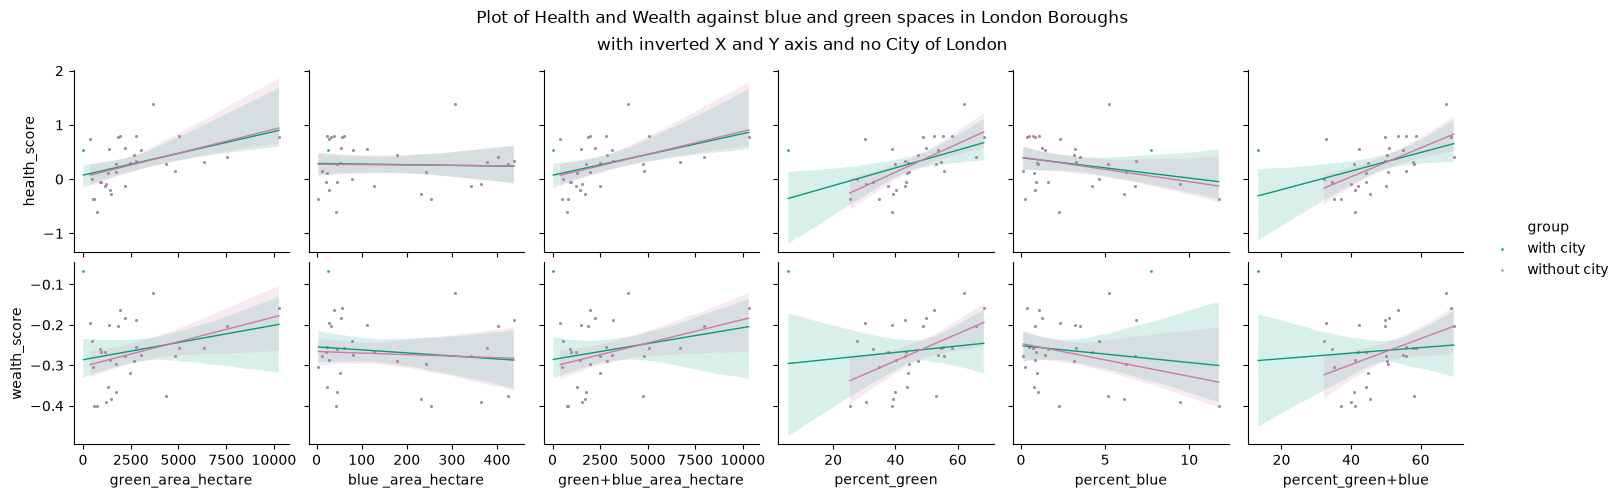

In [20]:
data_cl = data1.drop(index=31)

data1['group'] = 'with city'
data_cl['group'] = 'without city'

compared = pd.concat([data1, data_cl], ignore_index=True)

plot = sns.pairplot(data=compared,
             kind='reg', 
             y_vars = ['health_score', 'wealth_score'],
             x_vars = ['green_area_hectare', 'blue _area_hectare', 'green+blue_area_hectare',
                     'percent_green', 'percent_blue', 'percent_green+blue'],
             hue = 'group',
             palette = {
                 'with city': '#009E73',
                 'without city': '#CC79A7'
             },
             plot_kws={'scatter_kws': {'s': 1},
                       'line_kws': {'lw': 1}                        
                 
             })

#for ax in plot.axes[:, 0]:
#    ax=ax.invert_yaxis()

plot.fig.text(0.5,0.9, 'with inverted X and Y axis and no City of London', ha='center', fontsize=12)
plot.fig.subplots_adjust(top=0.86)
plt.suptitle('Plot of Health and Wealth against blue and green spaces in London Boroughs')
#plt.title('with inverted X and Y axis', y=1.9, x=-2.5)

plt.show()

In [30]:
df = data_cl
fig = px.scatter_3d(df, x='wealth_score', y='percent_green', z='health_score',
              title='Scatter Plot of Health against Green Spaces and Wealth', opacity=0.4)
fig.show()

## Comment on graph

In [22]:

data_cl.drop(columns='group').corr()

,green_area_hectare,blue _area_hectare,green+blue_area_hectare,percent_green,percent_blue,percent_green+blue,wealth_score,health_score,borough_area_hectare
green_area_hectare,1.000000,0.279030,0.998156,0.848488,-0.191679,0.858751,0.359834,0.446756,0.985320
blue _area_hectare,0.279030,1.000000,0.336810,0.123170,0.749990,0.348404,-0.072767,-0.023278,0.359006
green+blue_area_hectare,0.998156,0.336810,1.000000,0.839743,-0.140533,0.864045,0.348223,0.436580,0.988818
percent_green,0.848488,0.123170,0.839743,1.000000,-0.391903,0.964345,0.477802,0.643354,0.813135
percent_blue,-0.191679,0.749990,-0.140533,-0.391903,1.000000,-0.134453,-0.309245,-0.297350,-0.130612
percent_green+blue,0.858751,0.348404,0.864045,0.964345,-0.134453,1.000000,0.425674,0.607409,0.838239
wealth_score,0.359834,-0.072767,0.348223,0.477802,-0.309245,0.425674,1.000000,0.733931,0.295076
health_score,0.446756,-0.023278,0.436580,0.643354,-0.297350,0.607409,0.733931,1.000000,0.407855
borough_area_hectare,0.985320,0.359006,0.988818,0.813135,-0.130612,0.838239,0.295076,0.407855,1.000000


We can see a positive correlation between the percentage of a borough's area that is comprised of green space and wealth with health for residents (0.643335 and 0.733931 respectively) while the percentage of blue space shows a negative correlation with both health and wealth.

In [23]:
# Regression Analysis

import statsmodels.api as sm
formula_string = "Q('health_score') ~ Q('percent_green') + Q('wealth_score')"

model_full = sm.formula.ols(formula = formula_string, data = data_cl)
model_full_fitted = model_full.fit()

print(model_full_fitted.summary(),'\n','' \
'Green space (% of borough): ', model_full_fitted.pvalues["Q('percent_green')"],'\n',
'Wealth Score: ', model_full_fitted.pvalues["Q('wealth_score')"])

                            OLS Regression Results                            
Dep. Variable:      Q('health_score')   R-squared:                       0.650
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                     25.96
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           4.20e-07
Time:                        16:05:51   Log-Likelihood:                -2.0751
No. Observations:                  31   AIC:                             10.15
Df Residuals:                      28   BIC:                             14.45
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.4382      0

The regression analysis shows the wealth (through the wealth_score variable) and amount of green space relative to the borough size (through the percent_green variable) have a  statistically significant association with health scores (the dependent variable - health_score) for borough residents. The analysis shows that wealth and green space can explain $65\%$ of the variance in the health variable with $p\leq 0.05$ for each independent variable (when the other is held constant).


The analysis covers 31 Boroughs (excluding the City of London) and does not establish causation and only shows how the independent variables vary with the dependent variable.

<div align = 'center'>
<h2>Ai Declaration</h2>
</div>

<body>
The provided 'Tutor' AI was the only AI model used in the creation of this piece of work. Modifications to the instructions for the 'Tutor' Model have been made, the only modification was unrelated to the restrictions of the model and no edits to existing rules were made. The modifications consist only of an instruction to make the model say 'YABBA-DABBA-DOO' after each statements.

AI was used for basic debugging and syntax guidance.
</body>